# BigEarthNet — three additional baselines

Runs **ResNet-50, EfficientNet-B0 and ConvNeXt-Tiny only**. Defaults: BigEarthNet available subset, seed 13, 10 epochs, batch size 4, FP32 on CUDA when available. No PALT or ResNet-18 training is launched.

Enable Internet and a GPU in Kaggle, then run the cells in order. The supplied Drive archive is downloaded/extracted if missing. Existing files in this Kaggle session are reused. Official v2 metadata supplies labels and split assignments; coverage is recorded and subset results are clearly labeled.

The models train from scratch with 12 input bands and 19 multilabel outputs. They share the same preprocessing, AdamW optimizer, cosine scheduler, early-stopping rule and validation-only threshold selection. Compare these results only with BigEarthNet runs using the same samples and settings, not the previous EuroSAT smoke results.

Results are saved separately under `/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet`. Re-running training starts fresh; it does not resume interrupted checkpoints. Synthetic checks run for these three selected models before dataset loading.


## Training stability correction
FP32 training is enabled by default (`CFG.amp=False`) while retaining CUDA and the original model. This avoids FP16-specific overflows but does not guarantee all numerical failures are resolved. If AMP is explicitly enabled, non-finite gradients are detected before clipping, GradScaler skips that update and reduces its scale, and every skipped batch is logged. Ten overflows in one epoch stop the run. Strict checks remain active for FP32 failures. History is saved each epoch.

This version starts a fresh training run; it does not resume previous optimizer/scheduler state. Preserve earlier best.pt files before rerunning if needed. Apply the same precision setting to every compared model. Missing-positive-class AP warnings reflect subset label coverage, not a GPU error.

Validation of this correction: all code cells compiled and model-definition ASTs compared unchanged. No T4 execution was available for validation.


## Imagery-only archive fix
Your ZIP lacks labels. This version downloads official v2 metadata and matches patch IDs. Default `BEN_COVERAGE_MODE="available"` runs on the archive subset using official split assignments; it does not generate new splits. Coverage and subset status are saved in results. Empty official splits stop with an actionable error. Existing ZIP/extracted images are reused.


In [11]:
EXECUTION_MODE = "bigearthnet"  # BigEarthNet available subset; official split assignments
SEEDS = [13]  # Use the same seeds for all compared models.
assert EXECUTION_MODE in {"smoke", "eurosat", "bigearthnet"}
import importlib.util, subprocess, sys
# Preserve Kaggle's matched PyTorch/torchvision CUDA installation.
for module in ["torch","torchvision"]:
    if importlib.util.find_spec(module) is None:
        raise RuntimeError("Use a Kaggle Python GPU notebook with its bundled PyTorch/torchvision runtime.")
requirements={"gdown":"gdown>=5.2", "rasterio":"rasterio", "pyarrow":"pyarrow", "sklearn":"scikit-learn", "scipy":"scipy", "pandas":"pandas", "matplotlib":"matplotlib", "tqdm":"tqdm"}
missing=[package for module,package in requirements.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","--quiet",*missing])
print("Kaggle dependencies ready; execution mode:", EXECUTION_MODE)


Kaggle dependencies ready; execution mode: bigearthnet


In [12]:
import gc, hashlib, inspect, json, math, os, random, time, warnings
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, confusion_matrix, classification_report, average_precision_score,
    hamming_loss, label_ranking_average_precision_score)
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

@dataclass
class ExperimentConfig:
    data_dir: str = "/kaggle/working/palt_data"
    output_dir: str = "/kaggle/working/PALT_TGRS_results"
    batch_size: int = 4
    num_workers: int = 0  # Portable in Windows/Jupyter; increase in Linux if desired.
    epochs: int = 10
    patience: int = 8
    lr: float = 2e-4
    weight_decay: float = 1e-4
    split_seed: int = 42
    amp: bool = False  # FP32 troubleshooting default; GPU is still used.

CFG = ExperimentConfig()
OUT = Path(CFG.output_dir) / "drive_archives" / "three_additional_baselines" / EXECUTION_MODE
OUT.mkdir(parents=True, exist_ok=True)
DATA = Path(CFG.data_dir); DATA.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ACTIVE_SEEDS = SEEDS[:1] if EXECUTION_MODE == "smoke" else SEEDS
EPOCHS = 1 if EXECUTION_MODE == "smoke" else CFG.epochs
CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
FRACTIONS = [0.05, 0.10, 0.20, 0.30, 0.50]
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)
def worker_init_fn(worker_id):
    s = torch.initial_seed() % 2**32; random.seed(s); np.random.seed(s)
def make_loader(ds, shuffle=False, seed=42):
    if len(ds) == 0: raise ValueError("Empty dataset: check split files and dataset root.")
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle,
        num_workers=CFG.num_workers, pin_memory=DEVICE.type == "cuda",
        generator=torch.Generator().manual_seed(seed), worker_init_fn=worker_init_fn)
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
print("Configuration complete:", asdict(CFG), "torch", torch.__version__, "device", DEVICE)
(OUT / "configuration.json").write_text(json.dumps({**asdict(CFG), "mode": EXECUTION_MODE,
    "seeds": ACTIVE_SEEDS, "epochs": EPOCHS, "torch": torch.__version__}, indent=2))

Configuration complete: {'data_dir': '/kaggle/working/palt_data', 'output_dir': '/kaggle/working/PALT_TGRS_results', 'batch_size': 4, 'num_workers': 0, 'epochs': 10, 'patience': 8, 'lr': 0.0002, 'weight_decay': 0.0001, 'split_seed': 42, 'amp': False} torch 2.10.0+cu128 device cuda


325

## Google Drive download, safe unzip, and dataset verification
Uses your supplied ZIP links, not a TFDS download. Existing ZIPs are reused; extracted files are reused only after a completion record and file-size checks. Archives are checked for unsafe paths and available extraction space. Keep the archive unless you deliberately change the extraction workflow.

EuroSAT layout: 27,000 13-band GeoTIFFs in the ten class folders, or filenames such as `AnnualCrop_1.tif`. Three-band RGB ZIPs and serialized TFDS shards are rejected.

BigEarthNet layout: per-patch Sentinel-2 band TIFFs plus either v2 `metadata.parquet` (`patch_id`, `split`, `labels`) or v1 official `train/val/test` CSVs and per-patch label JSON. v2 and v1 are recorded separately in provenance. Imagery-only v2 ZIPs automatically download official metadata. The available mode explicitly selects matching archive images while retaining their official train/validation/test assignments, reports coverage, and labels subset results. Set BEN_COVERAGE_MODE="full" to require complete benchmark imagery. The split-file adapter supports both versions without relying on TorchGeo's changing constructor or requiring v2 segmentation masks. [BigEarthNet reference](https://bigearth.net/).

If Drive download fails, attach your ZIP using Kaggle **Add Input** and change its ZIP path below to the actual `/kaggle/input/...` path. `/kaggle/working/bigearthnet2.zip` is the default BigEarthNet archive path.


In [13]:
def stratified_take(ids, labels, count):
    ids = np.asarray(ids)
    if count >= len(ids): return ids.copy()
    chosen,_ = train_test_split(ids,train_size=count,stratify=labels[ids],random_state=CFG.split_seed)
    return np.sort(chosen)

def fixed_splits(y, fingerprint):
    path = DATA / f"eurosat_split_seed_{CFG.split_seed}.npz"
    if path.exists():
        with np.load(path) as saved:
            assert str(saved["fingerprint"]) == fingerprint, "Cache differs from saved split; use a new data_dir."
            ids = [saved[n].copy() for n in ("train","validation","test")]
    else:
        tr,other = train_test_split(np.arange(len(y)),test_size=5400,stratify=y,random_state=CFG.split_seed)
        va,te = train_test_split(other,test_size=2700,stratify=y[other],random_state=CFG.split_seed)
        ids = [np.sort(a) for a in (tr,va,te)]
        np.savez(path,train=ids[0],validation=ids[1],test=ids[2],fingerprint=fingerprint)
    assert [len(a) for a in ids] == [21600,2700,2700]
    assert len(np.unique(np.concatenate(ids))) == 27000
    assert np.array_equal(np.sort(np.concatenate(ids)),np.arange(27000))
    for label in range(10):
        counts = [int((y[a]==label).sum()) for a in ids]
        assert counts == [int((y==label).sum()*r) for r in (.8,.1,.1)]
    print("Train samples: 21600\nValidation samples: 2700\nTest samples: 2700")
    return ids


In [14]:
# This Drive archive contains imagery only, and may be a subset.
BEN_COVERAGE_MODE = "available"  # "full" requires every official eligible patch.
BEN_METADATA_URL = "https://zenodo.org/records/10891137/files/metadata.parquet?download=1"
BEN_METADATA_MIRROR = "https://huggingface.co/datasets/torchgeo/bigearthnet/resolve/3cf3a5910a5302d449fdb8e570e5b78de24fe07f/V2/metadata.parquet"

def ensure_ben_metadata(root):
    import urllib.request
    path=root/"metadata.parquet"
    if path.exists(): return path
    errors=[]
    for url in [BEN_METADATA_URL,BEN_METADATA_MIRROR]:
        partial=path.with_suffix(".parquet.partial")
        try:
            print("Downloading official BigEarthNet v2 labels and splits:",url)
            request=urllib.request.Request(url,headers={"User-Agent":"Mozilla/5.0"})
            with urllib.request.urlopen(request,timeout=120) as response, partial.open("wb") as dest:
                shutil.copyfileobj(response,dest,1024*1024)
            frame=pd.read_parquet(partial)
            if not {"patch_id","split","labels"}.issubset(frame.columns):
                raise ValueError(f"Unexpected metadata columns: {frame.columns.tolist()}")
            partial.replace(path)
            (root/"metadata_source.json").write_text(json.dumps({"url":url,"sha256":hashlib.sha256(path.read_bytes()).hexdigest()},indent=2))
            return path
        except Exception as e:
            print("Metadata source failed:",repr(e)); errors.append(f"{url}: {e}")
    raise RuntimeError("Metadata download failed. Enable Kaggle Internet or add official metadata.parquet to the extraction root. " + " | ".join(errors))

def match_ben_metadata(frame,index):
    if BEN_COVERAGE_MODE not in {"available","full"}: raise ValueError("Invalid BEN_COVERAGE_MODE")
    if frame.patch_id.astype(str).duplicated().any(): raise ValueError("Duplicate official metadata patch IDs")
    frame=frame.copy(); frame["patch_id"]=frame.patch_id.astype(str)
    frame["split"]=frame["split"].replace({"val":"validation"})
    if not set(frame["split"]).issubset({"train","validation","test"}): raise ValueError("Unknown official split values")
    available=set(index); official=set(frame.patch_id)
    absent=official-available; unmatched=available-official
    selected=frame[frame.patch_id.isin(available)].copy()
    if selected.empty: raise ValueError("No imagery IDs match v2 metadata. Verify the archive version and naming; labels cannot be guessed.")
    counts=selected.groupby("split").size().reindex(["train","validation","test"],fill_value=0)
    coverage=pd.DataFrame({"official":frame.groupby("split").size(),"available":counts}).fillna(0).astype(int)
    coverage.to_csv(OUT/"bigearthnet_coverage.csv")
    pd.Series(sorted(unmatched),name="patch_id").to_csv(OUT/"bigearthnet_unmatched_images.csv",index=False)
    print("Official / available patch counts:\n",coverage)
    print("Images without eligible metadata:",len(unmatched),"(excluded; may be snow/cloud patches or unknown IDs).")
    if absent and BEN_COVERAGE_MODE=="full":
        raise FileNotFoundError(f"Archive is missing {len(absent):,} official eligible patches. Full benchmark needs the complete imagery. Use available mode only for an explicitly labeled subset experiment.")
    if (counts==0).any():
        raise ValueError(f"This archive has no images in one or more official splits: {counts.to_dict()}. Add imagery from the missing splits; the loader will not invent a random split.")
    scope="available_subset" if absent else "full_official"
    print("EVALUATION SCOPE:",scope)
    if absent: print("SUBSET EXPERIMENT: official split assignments are preserved, but these results are NOT the full BigEarthNet benchmark.")
    selected[["patch_id","split"]].to_csv(OUT/"bigearthnet_selected_manifest.csv",index=False)
    (OUT/"bigearthnet_scope.json").write_text(json.dumps({"scope":scope,"coverage_mode":BEN_COVERAGE_MODE,"selected":len(selected),"official":len(frame),"unmatched_images":len(unmatched)},indent=2))
    return selected,scope

import shutil, zipfile, stat, re

import rasterio

from rasterio.enums import Resampling

EUROSAT_DRIVE_URL = "https://drive.google.com/file/d/1-raHylWPs7YUyOugKJ3MfiKrIrynREmd/view?usp=sharing"

BIGEARTHNET_DRIVE_URL = "https://drive.google.com/file/d/1IOSjnpIvwuPjOTeaZRK_0pQlZROU7183/view?usp=drive_link"

EUROSAT_ZIP = "/kaggle/working/eurosat.zip"

BIGEARTHNET_ZIP = "/kaggle/working/bigearthnet2.zip"

EUROSAT_EXTRACT_DIR = "/kaggle/working/datasets/eurosat"

BIGEARTHNET_EXTRACT_DIR = "/kaggle/working/datasets/bigearthnet"

def prepare_archive(url, zip_path, destination):
    archive=Path(zip_path); root=Path(destination); marker=root/".extraction_complete.json"
    if not archive.exists():
        import gdown
        if str(archive).startswith('/kaggle/input/'):
            raise FileNotFoundError(f"Kaggle input archive is missing: {archive}. Check Add Input and the ZIP filename.")
        archive.parent.mkdir(parents=True,exist_ok=True)
        partial=archive.with_suffix(archive.suffix+'.partial')
        print("Downloading Google Drive archive:",url,flush=True)
        try:
            result=gdown.download(url=url,output=str(partial),fuzzy=True,quiet=False,resume=True)
            if result is None or not zipfile.is_zipfile(partial):
                raise RuntimeError("The downloaded response is not a ZIP archive.")
            partial.replace(archive)
        except Exception as e:
            raise RuntimeError("Drive download failed. Enable Kaggle Internet, make the file accessible to anyone with the link, or attach the ZIP as a Kaggle Dataset and set its /kaggle/input path. Keep partial downloads for resume.") from e
    if not zipfile.is_zipfile(archive): raise ValueError(f"{archive} is not a valid ZIP. It may be a Drive HTML/quota response.")
    with zipfile.ZipFile(archive) as z:
        members=z.infolist()
        fingerprint=hashlib.sha256(json.dumps([(m.filename,m.CRC,m.file_size) for m in members]).encode()).hexdigest()
        if marker.exists():
            previous=json.loads(marker.read_text())
            if previous['fingerprint']!=fingerprint:
                raise RuntimeError("Archive changed. Set a new extraction directory to avoid mixing datasets.")
            if all((root/m.filename).is_file() and (root/m.filename).stat().st_size==m.file_size for m in members if not m.is_dir()):
                print("Reusing verified extraction:",root); return root,fingerprint
        root.mkdir(parents=True,exist_ok=True); resolved=root.resolve()
        pending=[]
        for m in members:
            target=(root/m.filename).resolve()
            if not target.is_relative_to(resolved) or stat.S_ISLNK(m.external_attr>>16):
                raise ValueError(f"Unsafe archive member: {m.filename}")
            if not m.is_dir() and (not target.is_file() or target.stat().st_size!=m.file_size): pending.append(m)
        needed=sum(m.file_size for m in pending)
        free=shutil.disk_usage(root).free
        print(f"ZIP: {archive.name}; files: {len(members):,}; extraction bytes needed: {needed:,}; free bytes: {free:,}")
        if needed>free: raise RuntimeError("Not enough Kaggle working disk space to unzip. Attach an already-extracted Kaggle Dataset or use a larger runtime.")
        # Re-extract existing unmarked files as well: a prior crash can leave a same-size corrupt file.
        for m in tqdm(members,desc="Unzip dataset"):
            if m.is_dir(): (root/m.filename).mkdir(parents=True,exist_ok=True); continue
            target=root/m.filename; target.parent.mkdir(parents=True,exist_ok=True)
            with z.open(m) as source, target.open('wb') as dest: shutil.copyfileobj(source,dest,1024*1024)
        marker.write_text(json.dumps({'fingerprint':fingerprint,'archive':str(archive),'files':len(members)},indent=2))
    print("Extraction complete:",root)
    return root,fingerprint

def raster_paths(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in {'.tif','.tiff'} and '__MACOSX' not in p.parts)

def read_multiband(path, channels, size=64):
    with rasterio.open(path) as src:
        if src.count!=channels: raise ValueError(f"{path}: {src.count} bands; expected {channels}. RGB cannot replace multispectral input.")
        x=src.read(out_shape=(channels,size,size),out_dtype='float32',resampling=Resampling.bilinear)
    if not np.isfinite(x).all(): raise ValueError(f"Non-finite reflectance in {path}")
    return x

class RasterEuroSAT(Dataset):
    def __init__(self,paths,y,ids,mean,std,augment):
        self.paths,self.y,self.ids=paths,y,np.asarray(ids)
        ops=[T.Resize((256,256),antialias=True)]
        ops += [T.RandomResizedCrop(224,scale=(.8,1.),antialias=True),T.RandomHorizontalFlip(),T.RandomVerticalFlip(),T.RandomRotation(30,interpolation=T.InterpolationMode.BILINEAR)] if augment else [T.CenterCrop(224)]
        self.transform=T.Compose(ops+[T.Normalize(mean.tolist(),std.tolist())])
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        idx=self.ids[i]
        return self.transform(torch.from_numpy(read_multiband(self.paths[idx],13))),torch.tensor(int(self.y[idx]),dtype=torch.long)

def eurosat_splits():
    root,fingerprint=prepare_archive(EUROSAT_DRIVE_URL,EUROSAT_ZIP,EUROSAT_EXTRACT_DIR)
    candidates=raster_paths(root); paths=[]; labels=[]
    for p in candidates:
        matches=[c for c in CLASSES if c in p.parts or p.stem.startswith(c+'_')]
        if len(matches)==1: paths.append(p); labels.append(CLASSES.index(matches[0]))
    if len(paths)!=27000:
        raise ValueError(f"Found {len(paths)} labeled GeoTIFFs, expected 27,000 EuroSAT-MS images. The ZIP must contain 13-band TIFFs in class folders or named Class_index.tif. RGB JPEG archives, TFDS shards and unrelated ZIPs are not silently converted. First entries: {[p.name for p in root.iterdir()][:12]}")
    y=np.asarray(labels,dtype=np.int64)
    read_multiband(paths[0],13)
    fingerprint=hashlib.sha256((fingerprint+'\n'+'\n'.join(str(p.relative_to(root)) for p in paths)).encode()).hexdigest()
    # Paths are sorted: sample indices have the same meaning in all three notebooks.
    pd.DataFrame({'source_index':np.arange(len(paths)),'path':[str(p.relative_to(root)) for p in paths],'class_id':y}).to_csv(DATA/'eurosat_source_manifest.csv',index=False)
    ids=fixed_splits(y,fingerprint)
    if EXECUTION_MODE=='smoke': ids=[stratified_take(a,y,n) for a,n in zip(ids,[1000,200,200])]
    np.savez(OUT/'used_split_indices.npz',train=ids[0],validation=ids[1],test=ids[2])
    total=np.zeros(13); sq=np.zeros(13); n=0
    for idx in tqdm(ids[0],desc='Training-only band statistics'):
        x=read_multiband(paths[idx],13).astype(np.float64)
        total+=x.sum((1,2)); sq+=(x*x).sum((1,2)); n+=x.shape[1]*x.shape[2]
    mean=(total/n).astype(np.float32); std=np.sqrt(np.maximum(sq/n-(total/n)**2,1e-12)).astype(np.float32)
    np.savez(OUT/'normalization.npz',mean=mean,std=std,training_ids=ids[0])
    datasets=tuple(RasterEuroSAT(paths,y,a,mean,std,i==0) for i,a in enumerate(ids))
    x,yb=next(iter(make_loader(datasets[1])))
    assert x.shape[1:]==(13,224,224) and yb.ndim==1
    print('Active split sizes:',*[len(d) for d in datasets]); print('Image shape:',list(x.shape),'Label shape:',list(yb.shape))
    print('EuroSAT archive preparation complete.')
    return datasets

BEN_CLASSES=['Urban fabric','Industrial or commercial units','Arable land','Permanent crops','Pastures','Complex cultivation patterns','Land principally occupied by agriculture, with significant areas of natural vegetation','Agro-forestry areas','Broad-leaved forest','Coniferous forest','Mixed forest','Natural grassland and sparsely vegetated areas','Moors, heathland and sclerophyllous vegetation','Transitional woodland, shrub','Beaches, dunes, sands','Inland wetlands','Coastal wetlands','Inland waters','Marine waters']

BEN_GROUPS=[['Continuous urban fabric','Discontinuous urban fabric'],['Industrial or commercial units'],['Non-irrigated arable land','Permanently irrigated land','Rice fields'],['Vineyards','Fruit trees and berry plantations','Olive groves','Annual crops associated with permanent crops'],['Pastures'],['Complex cultivation patterns'],['Land principally occupied by agriculture, with significant areas of natural vegetation'],['Agro-forestry areas'],['Broad-leaved forest'],['Coniferous forest'],['Mixed forest'],['Natural grassland','Sparsely vegetated areas'],['Moors and heathland','Sclerophyllous vegetation'],['Transitional woodland/shrub'],['Beaches, dunes, sands'],['Inland marshes','Peatbogs'],['Salt marshes','Salines'],['Water courses','Water bodies'],['Coastal lagoons','Estuaries','Sea and ocean']]

BEN_IGNORED={'Road and rail networks and associated land','Port areas','Airports','Mineral extraction sites','Dump sites','Construction sites','Green urban areas','Sport and leisure facilities','Bare rock','Burnt areas','Intertidal flats'}

BEN_BANDS=['B01','B02','B03','B04','B05','B06','B07','B08','B8A','B09','B11','B12']

def label_vector(names,version):
    if isinstance(names,str):
        try: names=json.loads(names)
        except json.JSONDecodeError as e: raise ValueError('Expected labels as a list of class names, not an arbitrary string.') from e
    mapping={name:i for i,name in enumerate(BEN_CLASSES)}
    if version=='v1': mapping.update({name:i for i,group in enumerate(BEN_GROUPS) for name in group})
    target=np.zeros(19,dtype=np.float32)
    for name in names:
        if name in mapping: target[mapping[name]]=1
        elif not (version=='v1' and name in BEN_IGNORED): raise ValueError(f'Unknown BigEarthNet label: {name}')
    return target

class DriveBigEarthNet(Dataset):
    def __init__(self,records,augment):
        self.records=records; self.ids=np.array([r[0] for r in records]); self.classes=BEN_CLASSES
        ops=[T.Resize((256,256),antialias=True)]
        ops += [T.RandomResizedCrop(224,scale=(.8,1.),antialias=True),T.RandomHorizontalFlip(),T.RandomVerticalFlip(),T.RandomRotation(30,interpolation=T.InterpolationMode.BILINEAR)] if augment else [T.CenterCrop(224)]
        self.transform=T.Compose(ops)
    def __len__(self): return len(self.records)
    def __getitem__(self,i):
        patch,paths,target=self.records[i]; bands=[]
        for p in paths:
            with rasterio.open(p) as src:
                if src.count!=1: raise ValueError(f'{p}: expected a single-band GeoTIFF.')
                bands.append(src.read(1,out_shape=(120,120),out_dtype='float32',resampling=Resampling.bilinear))
        x=torch.from_numpy(np.stack(bands))/10000.
        if x.shape[0]!=12 or not torch.isfinite(x).all(): raise ValueError(f'Invalid 12-band input: {patch}')
        return self.transform(x),torch.from_numpy(target.copy())

def bigearthnet_splits():
    import importlib.metadata
    try: print('Installed TorchGeo:',importlib.metadata.version('torchgeo'))
    except importlib.metadata.PackageNotFoundError: print('Using official split-file adapter; TorchGeo is not required.')
    root,fingerprint=prepare_archive(BIGEARTHNET_DRIVE_URL,BIGEARTHNET_ZIP,BIGEARTHNET_EXTRACT_DIR)
    print('Indexing Sentinel-2 band paths...')
    index={}
    for p in raster_paths(root):
        match=re.search(r'_(B\d{1,2}A?)$',p.stem,re.I)
        if not match: continue
        band=match.group(1).upper()
        if band not in BEN_BANDS and band[1:].isdigit(): band='B'+band[1:].zfill(2)
        if band not in BEN_BANDS: continue
        patch=p.stem[:match.start()]
        if band in index.setdefault(patch,{}): raise ValueError(f'Duplicate {patch} {band}; choose an extraction directory containing one dataset.')
        index[patch][band]=p
    metadata=list(root.rglob('metadata.parquet'))
    if not metadata:
        # Imagery-only v2 archives have neither labels nor official CSVs.
        csv_splits=[p for p in root.rglob('*.csv') if p.name in {'train.csv','bigearthnet-train.csv'}]
        if not csv_splits: metadata=[ensure_ben_metadata(root)]
    records={s:[] for s in ['train','validation','test']}; provenance={}
    if len(metadata)==1:
        version='v2'; frame=pd.read_parquet(metadata[0])
        if not {'patch_id','split','labels'}.issubset(frame.columns): raise ValueError(f'Unsupported v2 metadata columns: {frame.columns.tolist()}')
        provenance={'metadata':str(metadata[0]),'sha256':hashlib.sha256(metadata[0].read_bytes()).hexdigest()}
        frame,scope=match_ben_metadata(frame,index)
        entries=[(str(r.patch_id),str(r.split),r.labels) for r in frame.itertuples()]
    elif len(metadata)>1: raise ValueError('Multiple metadata.parquet files: select one BigEarthNet extraction directory.')
    else:
        version='v1'; scope='full_official'; entries=[]
        for split,aliases in [('train',['bigearthnet-train.csv','train.csv']),('validation',['bigearthnet-val.csv','val.csv','validation.csv']),('test',['bigearthnet-test.csv','test.csv'])]:
            candidates=[p for p in root.rglob('*.csv') if p.name in aliases]
            if len(candidates)!=1: raise FileNotFoundError(f'Expected one official {split} split CSV, found {len(candidates)}. v2 requires metadata.parquet; v1 requires its official train/val/test CSVs. No random-split fallback is used.')
            file=candidates[0]; provenance[split]={'file':str(file),'sha256':hashlib.sha256(file.read_bytes()).hexdigest()}
            import csv
            with file.open(newline='',encoding='utf-8-sig') as f:
                for row in csv.reader(f):
                    if not row: continue
                    patch=row[0].strip()
                    if patch.lower() in {'patch_id','s2_name','patch_name'}: continue
                    if patch not in index: raise FileNotFoundError(f'Official split image absent from ZIP: {patch}')
                    folder=next(iter(index[patch].values())).parent
                    label_file=folder/(patch+'_labels_metadata.json')
                    if not label_file.exists():
                        files=list(folder.glob('*.json'))
                        if len(files)!=1: raise FileNotFoundError(f'Cannot identify label JSON for {patch}')
                        label_file=files[0]
                    entries.append((patch,split,json.loads(label_file.read_text())['labels']))
    seen=set()
    for patch,split,names in tqdm(entries,desc='Validate official splits and 12 bands'):
        split={'val':'validation'}.get(split,split)
        if split not in records: raise ValueError(f'Unexpected official split {split!r}')
        if patch in seen: raise ValueError(f'Duplicate or overlapping official patch: {patch}')
        seen.add(patch)
        if patch not in index: raise FileNotFoundError(f'Archive lacks official {split} patch: {patch}. Full evaluation requires every manifest image; no silent subset filtering.')
        missing=set(BEN_BANDS)-index[patch].keys()
        if missing: raise ValueError(f'{patch}: missing spectral bands {missing}')
        records[split].append((patch,[index[patch][b] for b in BEN_BANDS],label_vector(names,version)))
    datasets=tuple(DriveBigEarthNet(records[s],s=='train') for s in records)
    if any(len(d)==0 for d in datasets): raise ValueError('An official BigEarthNet split is empty.')
    for split,d in zip(records,datasets):
        d.evaluation_scope=scope
        x,y=d[0]; assert x.shape==(12,224,224) and y.shape==(19,)
        print(split,len(d),'image',list(x.shape),'labels',list(y.shape))
    (OUT/'bigearthnet_provenance.json').write_text(json.dumps({'version':version,'evaluation_scope':scope,'archive_fingerprint':fingerprint,'split_files':provenance,'classes':BEN_CLASSES,'bands':BEN_BANDS},indent=2))
    (OUT/'bigearthnet_split_ids.json').write_text(json.dumps({s:d.ids.tolist() for s,d in zip(records,datasets)}))
    print('BigEarthNet',version,'official split preparation complete.')
    return datasets


## Model definitions and the three selected baselines
The existing model factory is retained; only `SELECTED_BASELINES` are validated and trained.


In [15]:
class OutputAdapter(nn.Module):
    def __init__(self, model): super().__init__(); self.model = model
    def forward(self, x): return {"logits": self.model(x)}


def replace_first_conv(module: nn.Module, in_channels: int):
    for name, child in module.named_children():
        if isinstance(child, nn.Conv2d):
            new = nn.Conv2d(in_channels, child.out_channels, child.kernel_size, child.stride,
                            child.padding, dilation=child.dilation, groups=child.groups, bias=child.bias is not None, padding_mode=child.padding_mode)
            nn.init.kaiming_normal_(new.weight, mode="fan_out", nonlinearity="relu")
            setattr(module, name, new); return True
        if replace_first_conv(child, in_channels): return True
    return False


def build_baseline(name: str, in_channels: int, num_classes: int):
    if name == "resnet18":
        m = models.resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "resnet50":
        m = models.resnet50(weights=None); m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=None); m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=None); m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    elif name == "vit_b_16":
        m = models.vit_b_16(weights=None); m.heads.head = nn.Linear(m.heads.head.in_features, num_classes)
    elif name == "swin_t":
        m = models.swin_t(weights=None); m.head = nn.Linear(m.head.in_features, num_classes)
    else: raise ValueError(name)
    if not replace_first_conv(m, in_channels): raise RuntimeError("First convolution not found")
    return OutputAdapter(m)


BASELINES = ["resnet18", "resnet50", "efficientnet_b0", "convnext_tiny", "vit_b_16", "swin_t"]
SELECTED_BASELINES = ["resnet50", "efficientnet_b0", "convnext_tiny"]


In [16]:
@dataclass
class PALTConfig:
    in_channels: int
    num_classes: int
    task: str = "single"  # single | multilabel
    image_size: int = 224
    patch_size: int = 16
    dim: int = 384
    heads: int = 6
    depth: int = 4
    prototypes: int = 32
    mlp_ratio: int = 4
    dropout: float = .1
    use_prototypes: bool = True
    use_liquid: bool = True
    use_feedback: bool = True
    use_pih: bool = True


class TransformerBlock(nn.Module):
    def __init__(self, d, h, ratio=4, drop=.1):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, h, dropout=drop, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, d*ratio), nn.GELU(), nn.Dropout(drop),
                                nn.Linear(d*ratio, d), nn.Dropout(drop))
    def forward(self, x):
        z = self.n1(x); x = x + self.attn(z,z,z,need_weights=False)[0]
        return x + self.ff(self.n2(x))


class PIH(nn.Module):
    # Prototype Interpretation Head: localization + prototype/class evidence.
    def __init__(self, d, h, k, c):
        super().__init__()
        self.cross = nn.MultiheadAttention(d, h, batch_first=True)
        self.importance = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
        self.classifier = nn.Linear(d, c, bias=False)
        self.bias = nn.Parameter(torch.zeros(c))
    def forward(self, tokens, memory):
        response, attn = self.cross(memory, tokens, tokens, need_weights=True, average_attn_weights=False)
        importance = torch.softmax(self.importance(response).squeeze(-1), dim=-1)
        proto_class = self.classifier(response)
        logits = (importance.unsqueeze(-1) * proto_class).sum(1) + self.bias
        return logits, importance, proto_class, attn


class PALT(nn.Module):
    def __init__(self, cfg: PALTConfig):
        super().__init__(); self.cfg = cfg
        assert cfg.image_size % cfg.patch_size == 0 and cfg.dim % cfg.heads == 0
        assert cfg.depth > 0 and cfg.prototypes > 0
        assert cfg.in_channels > 0 and cfg.num_classes > 1
        assert cfg.use_prototypes or not (cfg.use_liquid or cfg.use_feedback or cfg.use_pih)
        d, k = cfg.dim, cfg.prototypes
        self.patch = nn.Conv2d(cfg.in_channels, d, cfg.patch_size, cfg.patch_size)
        n = (cfg.image_size // cfg.patch_size) ** 2
        self.cls = nn.Parameter(torch.zeros(1,1,d)); self.pos = nn.Parameter(torch.randn(1,n+1,d)*.02)
        self.blocks = nn.ModuleList([TransformerBlock(d,cfg.heads,cfg.mlp_ratio,cfg.dropout) for _ in range(cfg.depth)])
        self.norm = nn.LayerNorm(d); self.backbone_head = nn.Linear(d,cfg.num_classes)
        self.prototype_head = nn.Linear(d,cfg.num_classes)
        self.proto = nn.Parameter(torch.randn(1,k,d)*.02)
        self.proto_cross = nn.MultiheadAttention(d,cfg.heads,batch_first=True)
        self.liquid_candidate = nn.Sequential(nn.LayerNorm(d),nn.Linear(d,d),nn.Tanh())
        self.tau = nn.Sequential(nn.LayerNorm(d),nn.Linear(d,1),nn.Sigmoid())
        self.feedback = nn.MultiheadAttention(d,cfg.heads,batch_first=True)
        self.pih = PIH(d,cfg.heads,k,cfg.num_classes)

    def forward(self, x):
        t = self.patch(x).flatten(2).transpose(1,2)
        cls = self.cls.expand(x.size(0),-1,-1); t = torch.cat([cls,t],1) + self.pos
        for b in self.blocks: t = b(t)
        t = self.norm(t)
        if not self.cfg.use_prototypes:
            return {"logits":self.backbone_head(t[:,0]), "tokens":t,"importance_scores":None,"prototype_class_scores":None,"attention_map":None,"memory":None,"diagnostics":{}}
        q = self.proto.expand(x.size(0),-1,-1)
        memory, init_attn = self.proto_cross(q,t,t,need_weights=True,average_attn_weights=False)
        diagnostics = {"initial_attention":init_attn}
        if self.cfg.use_liquid:
            candidate = self.liquid_candidate(memory)
            gate = self.tau(memory)
            memory = (1-gate)*memory + gate*candidate
            diagnostics["liquid_gate"] = gate
        if self.cfg.use_feedback:
            feedback, fb_attn = self.feedback(t,memory,memory,need_weights=True,average_attn_weights=False)
            t = self.norm(t + feedback); diagnostics["feedback_attention"] = fb_attn
        if not self.cfg.use_pih:
            logits = self.backbone_head(t[:,0]) + self.prototype_head(memory.mean(1))
            return {"logits":logits,"tokens":t,"memory":memory,"diagnostics":diagnostics,"importance_scores":None,"prototype_class_scores":None,"attention_map":init_attn}
        logits, importance, proto_class, attn = self.pih(t,memory)
        return {"logits":logits,"tokens":t,"memory":memory,"importance_scores":importance,
                "prototype_class_scores":proto_class,"attention_map":attn,"diagnostics":diagnostics}


def build_palt(in_channels, num_classes, task="single", variant="full"):
    switches = {
        "backbone": dict(use_prototypes=False,use_liquid=False,use_feedback=False,use_pih=False),
        "prototype": dict(use_prototypes=True,use_liquid=False,use_feedback=False,use_pih=False),
        "prototype+pih": dict(use_prototypes=True,use_liquid=False,use_feedback=False,use_pih=True),
        "prototype+liquid+pih": dict(use_prototypes=True,use_liquid=True,use_feedback=False,use_pih=True),
        "full": dict(use_prototypes=True,use_liquid=True,use_feedback=True,use_pih=True),
    }
    return PALT(PALTConfig(in_channels=in_channels,num_classes=num_classes,task=task,**switches[variant]))
ABLATIONS = ["backbone","prototype","prototype+pih","prototype+liquid+pih","full"]
print("Model definitions complete; full PALT config:", asdict(build_palt(13,10).cfg))

Model definitions complete; full PALT config: {'in_channels': 13, 'num_classes': 10, 'task': 'single', 'image_size': 224, 'patch_size': 16, 'dim': 384, 'heads': 6, 'depth': 4, 'prototypes': 32, 'mlp_ratio': 4, 'dropout': 0.1, 'use_prototypes': True, 'use_liquid': True, 'use_feedback': True, 'use_pih': True}


## Shared training, task metrics and saved artifacts

In [17]:
def metric_dict(y,p,task,threshold=.5):
    if task == "single":
        pred=p.argmax(1); labels=np.arange(p.shape[1])
        return dict(accuracy=accuracy_score(y,pred),macro_precision=precision_score(y,pred,labels=labels,average="macro",zero_division=0),
            macro_recall=recall_score(y,pred,labels=labels,average="macro",zero_division=0),
            macro_f1=f1_score(y,pred,labels=labels,average="macro",zero_division=0),
            weighted_f1=f1_score(y,pred,labels=labels,average="weighted",zero_division=0),kappa=cohen_kappa_score(y,pred,labels=labels))
    pred=(p>=threshold).astype(int)
    return dict(macro_f1=f1_score(y,pred,average="macro",zero_division=0),micro_f1=f1_score(y,pred,average="micro",zero_division=0),
        macro_mAP=average_precision_score(y,p,average="macro"),micro_mAP=average_precision_score(y,p,average="micro"),
        hamming_loss=hamming_loss(y,pred),label_ranking_AP=label_ranking_average_precision_score(y,p))

def checked_loss(logits,y,task):
    if task == "single":
        if y.ndim != 1 or y.dtype != torch.long: raise ValueError("Single-label targets must be int64 [B].")
        loss=F.cross_entropy(logits,y)
    else:
        if y.shape != logits.shape or not torch.all((y==0)|(y==1)): raise ValueError("Multilabel targets must be binary [B,19].")
        loss=F.binary_cross_entropy_with_logits(logits,y.float())
    if not torch.isfinite(loss): raise FloatingPointError("NaN/Inf loss: inspect input bands, normalization, and learning rate.")
    return loss

@torch.no_grad()
def evaluate(model,loader,task,threshold=.5):
    model.eval(); ys=[]; ps=[]; total=0.; count=0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE); logits=model(x)["logits"]
        loss=checked_loss(logits,y,task); total+=loss.item()*len(x); count+=len(x)
        ys.append(y.cpu()); ps.append((logits.softmax(1) if task=="single" else logits.sigmoid()).cpu())
    if count==0: raise ValueError("Empty evaluation loader.")
    y=torch.cat(ys).numpy(); p=torch.cat(ps).numpy()
    return {"loss":total/count,**metric_dict(y,p,task,threshold)},y,p

def restore(model,path):
    if not path.is_file(): raise FileNotFoundError(f"Missing best checkpoint: {path}. Complete training first.")
    ckpt=torch.load(path,map_location=DEVICE,weights_only=False)
    model.load_state_dict(ckpt["model"]); return ckpt

def fit(model,train_loader,val_loader,task,run_dir):
    model.to(DEVICE); run_dir.mkdir(parents=True,exist_ok=True)
    print("Training precision:", "FP16 AMP" if CFG.amp and DEVICE.type=="cuda" else "FP32", "device:", DEVICE, flush=True)
    overflow_events=[]
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.lr,weight_decay=CFG.weight_decay)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,EPOCHS,eta_min=1e-6)
    scaler=torch.amp.GradScaler("cuda",enabled=CFG.amp and DEVICE.type=="cuda")
    best=-float("inf"); bad=0; history=[]; active=0; sync(); start=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train(); total=0.; count=0; skipped=0
        for x,y in tqdm(train_loader,desc=f"{run_dir.name}: epoch {epoch}/{EPOCHS}",leave=False):
            x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,enabled=CFG.amp and DEVICE.type=="cuda"):
                loss=checked_loss(model(x)["logits"],y,task)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            gradients=[p.grad for p in model.parameters() if p.grad is not None]
            finite=bool(torch.stack([torch.isfinite(g).all() for g in gradients]).all())
            if not finite:
                if not scaler.is_enabled():
                    raise FloatingPointError("Non-finite FP32 gradients: stop and inspect inputs/model; this is not an AMP scaling overflow. No optimizer update was applied.")
                old_scale=scaler.get_scale()
                scaler.step(opt)  # GradScaler detects non-finite gradients and skips the optimizer update.
                scaler.update(); opt.zero_grad(set_to_none=True)
                skipped+=1
                overflow_events.append({"epoch":epoch,"skipped_batch":skipped,"old_scale":old_scale,"new_scale":scaler.get_scale()})
                pd.DataFrame(overflow_events).to_csv(run_dir/"amp_overflows.csv",index=False)
                print("AMP overflow: update skipped, scale reduced",old_scale,"->",scaler.get_scale(),flush=True)
                if skipped>=10:
                    raise FloatingPointError("Repeated AMP overflows in this epoch. Set CFG.amp=False and restart this run in FP32.")
                continue
            nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True)
            active=max(active,sum(p.numel() for p in model.parameters() if p.grad is not None))
            scaler.step(opt); scaler.update(); total+=loss.item()*len(x); count+=len(x)
        if count==0: raise ValueError("Empty training loader.")
        metrics,_,_=evaluate(model,val_loader,task); score=metrics["macro_f1"]
        history.append({"epoch":epoch,"train_loss":total/count,"amp_skipped_batches":skipped,"lr":opt.param_groups[0]["lr"],**metrics}); print(history[-1],flush=True); pd.DataFrame(history).to_csv(run_dir/"history.csv",index=False); sched.step()
        if score>best+1e-5:
            best=score; bad=0
            torch.save({"model":model.state_dict(),"epoch":epoch,"validation":metrics,
                "architecture":asdict(model.cfg) if isinstance(model,PALT) else str(type(model.model)),
                "training":asdict(CFG)},run_dir/"best.pt")
        else: bad+=1
        if bad>=CFG.patience: print("Early stopping at",epoch); break
    sync(); elapsed=time.perf_counter()-start
    h=pd.DataFrame(history); h.to_csv(run_dir/"history.csv",index=False)
    fig,ax=plt.subplots(); ax.plot(h.epoch,h.train_loss,label="train"); ax.plot(h.epoch,h.loss,label="validation"); ax.legend(); ax.set(xlabel="Epoch",ylabel="Loss"); fig.savefig(run_dir/"learning_curves.png",bbox_inches="tight"); plt.close(fig)
    ckpt=restore(model,run_dir/"best.pt")
    return {"best_validation_epoch":ckpt["epoch"],"training_seconds":elapsed,"active_parameters":active}

@torch.no_grad()
def latency(model,ds):
    model.eval(); x=ds[0][0][None].to(DEVICE)
    for _ in range(3): model(x)
    sync(); start=time.perf_counter()
    for _ in range(20): model(x)
    sync(); return 1000*(time.perf_counter()-start)/20

def run_one(name,dataset_name,datasets,seed,task,channels,classes,variant="full",suite="baseline"):
    seed_everything(seed); run_dir=OUT/dataset_name/suite/name/variant/f"seed_{seed}"
    print("Starting",dataset_name,suite,name,variant,"seed",seed)
    train,val,test=datasets
    model=build_baseline(name,channels,classes) if name in BASELINES else build_palt(channels,classes,task,variant)
    try:
        trained=fit(model,make_loader(train,True,seed),make_loader(val,False,seed),task,run_dir)
        threshold=.5
        if task=="multilabel":
            _,vy,vp=evaluate(model,make_loader(val),task)
            grid=np.arange(.05,.951,.05); scores=[f1_score(vy,vp>=t,average="macro",zero_division=0) for t in grid]
            threshold=float(grid[int(np.argmax(scores))])
            (run_dir/"threshold.json").write_text(json.dumps({"threshold":threshold,"selection":"validation macro-F1","grid":grid.tolist()}))
        metrics,y,p=evaluate(model,make_loader(test),task,threshold)
        pred=p.argmax(1) if task=="single" else (p>=threshold).astype(int)
        row={"dataset":dataset_name,"model":name,"variant":variant,"seed":seed,
            "evaluation_scope":getattr(test,"evaluation_scope","full_or_smoke"),"parameters":sum(q.numel() for q in model.parameters()),"latency_ms_per_image":latency(model,test),**trained,**metrics}
        if task=="multilabel": row["threshold"]=threshold
        pd.DataFrame([row]).to_csv(run_dir/"test_metrics.csv",index=False)
        np.savez_compressed(run_dir/"predictions.npz",targets=y,probabilities=p,predictions=pred,
            sample_ids=test.ids if hasattr(test,"ids") else np.arange(len(test)))
        report=classification_report(y,pred,labels=np.arange(classes),target_names=CLASSES if task=="single" else test.classes,output_dict=True,zero_division=0)
        pd.DataFrame(report).T.to_csv(run_dir/"classification_report.csv")
        if task=="single":
            cm=confusion_matrix(y,pred,labels=np.arange(classes)); pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(run_dir/"confusion_matrix.csv")
            fig,ax=plt.subplots(figsize=(9,8)); im=ax.imshow(cm); fig.colorbar(im,ax=ax); ax.set(xticks=range(10),yticks=range(10),xticklabels=CLASSES,yticklabels=CLASSES,xlabel="Predicted",ylabel="True"); plt.setp(ax.get_xticklabels(),rotation=90); fig.tight_layout(); fig.savefig(run_dir/"confusion_matrix.png"); plt.close(fig)
        else:
            table=pd.DataFrame({"class":test.classes,"precision":precision_score(y,pred,average=None,zero_division=0),"recall":recall_score(y,pred,average=None,zero_division=0),"f1":f1_score(y,pred,average=None,zero_division=0),"AP":average_precision_score(y,p,average=None)})
            table.to_csv(run_dir/"per_class_metrics.csv",index=False)
        print("Run complete:",row); return row
    except torch.cuda.OutOfMemoryError as e:
        raise RuntimeError("CUDA out of memory. Reduce CFG.batch_size for ALL compared models and rerun the suite; architecture was not changed.") from e
    finally:
        del model; gc.collect()
        if DEVICE.type=="cuda": torch.cuda.empty_cache()

def summarize(rows,name):
    raw=pd.DataFrame(rows); raw.to_csv(OUT/f"{name}_raw.csv",index=False)
    metrics=[c for c in raw.select_dtypes(include=np.number) if c!="seed"]
    summary=raw.groupby(["dataset","model","variant","evaluation_scope"])[metrics].agg(["mean","std"])
    summary.columns=[f"{a}_{b}" for a,b in summary.columns]; summary=summary.reset_index()
    summary.to_csv(OUT/f"{name}_aggregate.csv",index=False)
    readable=summary[["dataset","model","variant","evaluation_scope"]].copy()
    for m in metrics:
        readable[m]=[f"{a:.5g} ± {b:.3g}" if pd.notna(b) else f"{a:.5g} (one seed; SD undefined)" for a,b in zip(summary[m+"_mean"],summary[m+"_std"])]
    display(readable); return summary

## Synthetic forward and metric checks

In [18]:
VALIDATION_CASES = [(name,"full") for name in SELECTED_BASELINES]
def synthetic_validation():
    seed_everything(7)
    channels, classes, task = (12,19,"multilabel") if EXECUTION_MODE=="bigearthnet" else (13,10,"single")
    x=torch.randn(1,channels,224,224)
    cases=VALIDATION_CASES
    results=[]
    for name,variant in cases:
        model=build_baseline(name,channels,classes) if name in BASELINES else build_palt(channels,classes,task,variant)
        model.eval()
        with torch.no_grad(): out=model(x)
        assert out["logits"].shape==(1,classes) and torch.isfinite(out["logits"]).all()
        target=torch.zeros(1,classes) if task=="multilabel" else torch.tensor([2])
        assert checked_loss(out["logits"],target,task).isfinite()
        if name=="palt":
            assert {"logits","importance_scores","prototype_class_scores","attention_map","memory","diagnostics"}<=out.keys()
            assert len(model.blocks)==model.cfg.depth==4 and model.proto.shape[1]==model.cfg.prototypes==32
            if model.cfg.use_pih:
                assert out["attention_map"].shape==(1,6,32,197)
                assert out["importance_scores"].shape==(1,32)
                assert out["prototype_class_scores"].shape==(1,32,classes)
                assert out["memory"].shape==(1,32,384)
            if variant=="prototype":
                model.zero_grad(); model(x)["logits"].sum().backward()
                assert model.prototype_head.weight.grad.abs().sum()>0 and model.proto.grad.abs().sum()>0
        results.append(f"{name}/{variant}: forward, loss and output shapes PASS")
        del model,out; gc.collect()
    assert checked_loss(torch.tensor([[2.,0.]]),torch.tensor([0]),"single").isfinite()
    assert checked_loss(torch.tensor([[2.,-2.]]),torch.tensor([[1.,0.]]),"multilabel").isfinite()
    y=np.array([0,1,0,1]); p=np.array([[.9,.1],[.1,.9],[.8,.2],[.2,.8]])
    assert all(np.isclose(v,1) for v in metric_dict(y,p,"single").values())
    bad=metric_dict(y,1-p,"single"); assert bad["accuracy"]==0 and bad["kappa"]==-1
    y2=np.array([[1,0],[0,1],[1,1]]); p2=np.array([[.9,.1],[.1,.9],[.8,.8]])
    m=metric_dict(y2,p2,"multilabel"); assert m["hamming_loss"]==0
    assert all(np.isclose(v,1) for k,v in m.items() if k!="hamming_loss")
    results.append("Single-label/multilabel losses and toy metrics PASS")
    (OUT/"synthetic_validation.json").write_text(json.dumps(results,indent=2))
    print("Synthetic validation complete:\n"+"\n".join(results))
    return results
synthetic_results=synthetic_validation()

Synthetic validation complete:
resnet50/full: forward, loss and output shapes PASS
efficientnet_b0/full: forward, loss and output shapes PASS
convnext_tiny/full: forward, loss and output shapes PASS
Single-label/multilabel losses and toy metrics PASS


## Execute comparison

In [19]:
if EXECUTION_MODE in {"smoke","eurosat"}:
    datasets=eurosat_splits(); dataset_name="EuroSAT-MS"; task="single"; channels=13; classes=10
else:
    datasets=bigearthnet_splits(); dataset_name="BigEarthNet-S2"; task="multilabel"; channels=12; classes=19
names=SELECTED_BASELINES.copy()
print("Selected models:", names, "epochs:", EPOCHS, "seeds:", ACTIVE_SEEDS, flush=True)
rows=[]
for seed in ACTIVE_SEEDS:
    for name in names:
        rows.append(run_one(name,dataset_name,datasets,seed,task,channels,classes,suite="comparison"))
        pd.DataFrame(rows).to_csv(OUT/"three_baselines_raw.csv",index=False)
summarize(rows,"three_baselines")
print("Baseline comparison complete:",dataset_name,names)
if EXECUTION_MODE=="smoke": print("One-epoch smoke metrics are NOT publication results.")

Using official split-file adapter; TorchGeo is not required.


Downloading...
From (original): https://drive.google.com/uc?id=1IOSjnpIvwuPjOTeaZRK_0pQlZROU7183
From (redirected): https://drive.google.com/uc?id=1IOSjnpIvwuPjOTeaZRK_0pQlZROU7183&confirm=t&uuid=d542a2bd-9e77-444e-b909-08416f529155
To: /kaggle/working/bigearthnet2.zip.partial
100%|██████████| 3.50G/3.50G [00:51<00:00, 68.1MB/s]


ZIP: bigearthnet2.zip; files: 347,244; extraction bytes needed: 4,761,872,720; free bytes: 12,297,654,272


Unzip dataset:   0%|          | 0/347244 [00:00<?, ?it/s]

Extraction complete: /kaggle/working/datasets/bigearthnet
Indexing Sentinel-2 band paths...
Metadata source failed: <HTTPError 403: 'Forbidden'>
Official / available patch counts:
             official  available
split                          
test          119825       6506
train         237871      12615
validation    122342       6226
Images without eligible metadata: 3590 (excluded; may be snow/cloud patches or unknown IDs).
EVALUATION SCOPE: available_subset
SUBSET EXPERIMENT: official split assignments are preserved, but these results are NOT the full BigEarthNet benchmark.


Validate official splits and 12 bands:   0%|          | 0/25347 [00:00<?, ?it/s]

... (95 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


Run complete: {'dataset': 'BigEarthNet-S2', 'model': 'convnext_tiny', 'variant': 'full', 'seed': 13, 'evaluation_scope': 'available_subset', 'parameters': 27848563, 'latency_ms_per_image': 9.439333050067944, 'best_validation_epoch': 10, 'training_seconds': 8559.670392778, 'active_parameters': 27848563, 'loss': 0.15457527510957236, 'macro_f1': 0.4544777551039825, 'micro_f1': 0.7511223413389594, 'macro_mAP': np.float64(0.483768659908629), 'micro_mAP': np.float64(0.8427949015967132), 'hamming_loss': 0.0820699920720954, 'label_ranking_AP': np.float64(0.8852914508037213), 'threshold': 0.2}


,dataset,model,variant,evaluation_scope,parameters,latency_ms_per_image,best_validation_epoch,training_seconds,active_parameters,loss,macro_f1,micro_f1,macro_mAP,micro_mAP,hamming_loss,label_ranking_AP,threshold
0,BigEarthNet-S2,convnext_tiny,full,available_subset,2.7849e+07 (one seed; SD undefined),9.4393 (one seed; SD undefined),10 (one seed; SD undefined),8559.7 (one seed; SD undefined),2.7849e+07 (one seed; SD undefined),0.15458 (one seed; SD undefined),0.45448 (one seed; SD undefined),0.75112 (one seed; SD undefined),0.48377 (one seed; SD undefined),0.84279 (one seed; SD undefined),0.08207 (one seed; SD undefined),0.88529 (one seed; SD undefined),0.2 (one seed; SD undefined)
1,BigEarthNet-S2,efficientnet_b0,full,available_subset,4.0345e+06 (one seed; SD undefined),8.5538 (one seed; SD undefined),10 (one seed; SD undefined),7359.6 (one seed; SD undefined),4.0345e+06 (one seed; SD undefined),0.14212 (one seed; SD undefined),0.49322 (one seed; SD undefined),0.7672 (one seed; SD undefined),0.52466 (one seed; SD undefined),0.86935 (one seed; SD undefined),0.074296 (one seed; SD undefined),0.91722 (one seed; SD undefined),0.25 (one seed; SD undefined)
2,BigEarthNet-S2,resnet50,full,available_subset,2.3575e+07 (one seed; SD undefined),7.7768 (one seed; SD undefined),10 (one seed; SD undefined),8151.5 (one seed; SD undefined),2.3575e+07 (one seed; SD undefined),0.15277 (one seed; SD undefined),0.48886 (one seed; SD undefined),0.77674 (one seed; SD undefined),0.5066 (one seed; SD undefined),0.85886 (one seed; SD undefined),0.068131 (one seed; SD undefined),0.9222 (one seed; SD undefined),0.3 (one seed; SD undefined)


Baseline comparison complete: BigEarthNet-S2 ['resnet50', 'efficientnet_b0', 'convnext_tiny']


## Final results and saved files

In [22]:
print("Final results:", OUT.resolve())
if EXECUTION_MODE=="smoke": print("SMOKE METRICS ARE NOT PUBLICATION RESULTS.")
all_csv_tables={}
for path in sorted(OUT.rglob("*.csv")):
    all_csv_tables[str(path.resolve())]=pd.read_csv(path)
    if path.parent==OUT and "aggregate" in path.name:
        print(path.name)
        display(pd.read_csv(path,header=[0,1],index_col=0) if path.name.startswith("pih_") else all_csv_tables[str(path.resolve())])
artifacts=sorted(str(p.resolve()) for p in OUT.rglob("*") if p.is_file())
(OUT/"artifact_inventory.json").write_text(json.dumps(artifacts,indent=2))
print("Loaded CSV files:",len(all_csv_tables))
for path in artifacts: print(path)
print("Results complete. Single-seed standard deviation is undefined.")

Final results: /kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet
three_baselines_aggregate.csv


,dataset,model,variant,evaluation_scope,parameters_mean,parameters_std,latency_ms_per_image_mean,latency_ms_per_image_std,best_validation_epoch_mean,best_validation_epoch_std,...,macro_mAP_mean,macro_mAP_std,micro_mAP_mean,micro_mAP_std,hamming_loss_mean,hamming_loss_std,label_ranking_AP_mean,label_ranking_AP_std,threshold_mean,threshold_std
0,BigEarthNet-S2,convnext_tiny,full,available_subset,27848563.0,NaN,9.439333,NaN,10.0,NaN,...,0.483769,NaN,0.842795,NaN,0.082070,NaN,0.885291,NaN,0.20,NaN
1,BigEarthNet-S2,efficientnet_b0,full,available_subset,4034479.0,NaN,8.553758,NaN,10.0,NaN,...,0.524658,NaN,0.869353,NaN,0.074296,NaN,0.917222,NaN,0.25,NaN
2,BigEarthNet-S2,resnet50,full,available_subset,23575187.0,NaN,7.776767,NaN,10.0,NaN,...,0.506599,NaN,0.858858,NaN,0.068131,NaN,0.922202,NaN,0.30,NaN


Loaded CSV files: 17
/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet/BigEarthNet-S2/comparison/convnext_tiny/full/seed_13/best.pt
/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet/BigEarthNet-S2/comparison/convnext_tiny/full/seed_13/classification_report.csv
/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet/BigEarthNet-S2/comparison/convnext_tiny/full/seed_13/history.csv
/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet/BigEarthNet-S2/comparison/convnext_tiny/full/seed_13/learning_curves.png
/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet/BigEarthNet-S2/comparison/convnext_tiny/full/seed_13/per_class_metrics.csv
/kaggle/working/PALT_TGRS_results/drive_archives/three_additional_baselines/bigearthnet/BigEarthNet-S2/comparison/convnext_tiny/full/seed_13/predictions.npz
/kaggle/working/PALT_TGRS_res

## Validation before delivery
Notebook JSON structure, all Python cell compilations, selected-model execution wiring, and preservation of original model definitions were checked locally. This revised three-model BigEarthNet run has not been executed on Kaggle. Prior EuroSAT smoke outputs were removed to avoid presenting them as results of this configuration.


In [23]:
from pathlib import Path
import pandas as pd
import shutil
from IPython.display import display, FileLink

RESULTS_DIR = Path(
    "/kaggle/working/PALT_TGRS_results/drive_archives/"
    "three_additional_baselines/bigearthnet"
)

# Read saved test results—no retraining.
files = sorted(RESULTS_DIR.glob(
    "BigEarthNet-S2/comparison/*/full/seed_13/test_metrics.csv"
))

if not files:
    raise FileNotFoundError(f"No baseline results found in {RESULTS_DIR}")

results = pd.concat(
    [pd.read_csv(path) for path in files],
    ignore_index=True
)

expected = {"resnet50", "efficientnet_b0", "convnext_tiny"}
missing = expected - set(results["model"])
if missing:
    raise RuntimeError(f"Missing completed baseline results: {missing}")

table = results[[
    "model", "seed", "macro_f1", "micro_f1",
    "macro_mAP", "micro_mAP", "hamming_loss",
    "parameters", "latency_ms_per_image",
    "best_validation_epoch", "threshold"
]].copy()

percentage_columns = [
    "macro_f1", "micro_f1", "macro_mAP",
    "micro_mAP", "hamming_loss"
]
table[percentage_columns] *= 100
table = table.rename(columns={
    name: f"{name} (%)" for name in percentage_columns
})

print("FINAL BIGEARTHNET BASELINE TEST RESULTS")
print("Scope: available subset; seed 13; 10-epoch budget.")
display(table.round(4))
table.to_csv(RESULTS_DIR / "final_baseline_table.csv", index=False)

# Verify important artifacts before packaging.
required = [
    "best.pt",
    "predictions.npz",
    "test_metrics.csv",
    "per_class_metrics.csv",
    "classification_report.csv",
    "history.csv",
    "learning_curves.png",
    "threshold.json",
]

missing_artifacts = [
    str(path.parent / filename)
    for path in files
    for filename in required
    if not (path.parent / filename).is_file()
]

if missing_artifacts:
    raise FileNotFoundError(
        "Missing artifacts:\n" + "\n".join(missing_artifacts)
    )

zip_path = shutil.make_archive(
    "/kaggle/working/BigEarthNet_Three_Baselines_Complete",
    "zip",
    root_dir=str(RESULTS_DIR),
)

print("\nAll required baseline artifacts found.")
print("Results ZIP:", zip_path)
print(f"ZIP size: {Path(zip_path).stat().st_size / 1024**2:.1f} MB")
display(FileLink(zip_path))

FINAL BIGEARTHNET BASELINE TEST RESULTS
Scope: available subset; seed 13; 10-epoch budget.


,model,seed,macro_f1 (%),micro_f1 (%),macro_mAP (%),micro_mAP (%),hamming_loss (%),parameters,latency_ms_per_image,best_validation_epoch,threshold
0,convnext_tiny,13,45.4478,75.1122,48.3769,84.2795,8.2070,27848563,9.4393,10,0.20
1,efficientnet_b0,13,49.3215,76.7199,52.4658,86.9353,7.4296,4034479,8.5538,10,0.25
2,resnet50,13,48.8860,77.6735,50.6599,85.8858,6.8131,23575187,7.7768,10,0.30



All required baseline artifacts found.
Results ZIP: /kaggle/working/BigEarthNet_Three_Baselines_Complete.zip
ZIP size: 198.5 MB


/kaggle/working/BigEarthNet_Three_Baselines_Complete.zip


convnext_tiny — test threshold: 0.20


,class,TN,FP,FN,TP,test_positive_support,precision,recall,f1
0,Urban fabric,5822,497,45,142,187,0.2222,0.7594,0.3438
1,Industrial or commercial units,6429,41,32,4,36,0.0889,0.1111,0.0988
2,Arable land,4546,467,241,1252,1493,0.7283,0.8386,0.7796
3,Permanent crops,6497,0,9,0,9,0.0000,0.0000,0.0000
4,Pastures,5971,303,108,124,232,0.2904,0.5345,0.3763
5,Complex cultivation patterns,5548,437,41,480,521,0.5234,0.9213,0.6676
6,Agriculture with natural vegetation,4523,1039,230,714,944,0.4073,0.7564,0.5295
7,Agro-forestry areas,6506,0,0,0,0,0.0000,0.0000,0.0000
8,Broad-leaved forest,5374,384,340,408,748,0.5152,0.5455,0.5299
9,Coniferous forest,2050,1741,21,2694,2715,0.6074,0.9923,0.7536


No positive test examples for: ['Agro-forestry areas', 'Coastal wetlands']
Recall/F1 for these labels are not meaningfully estimable.


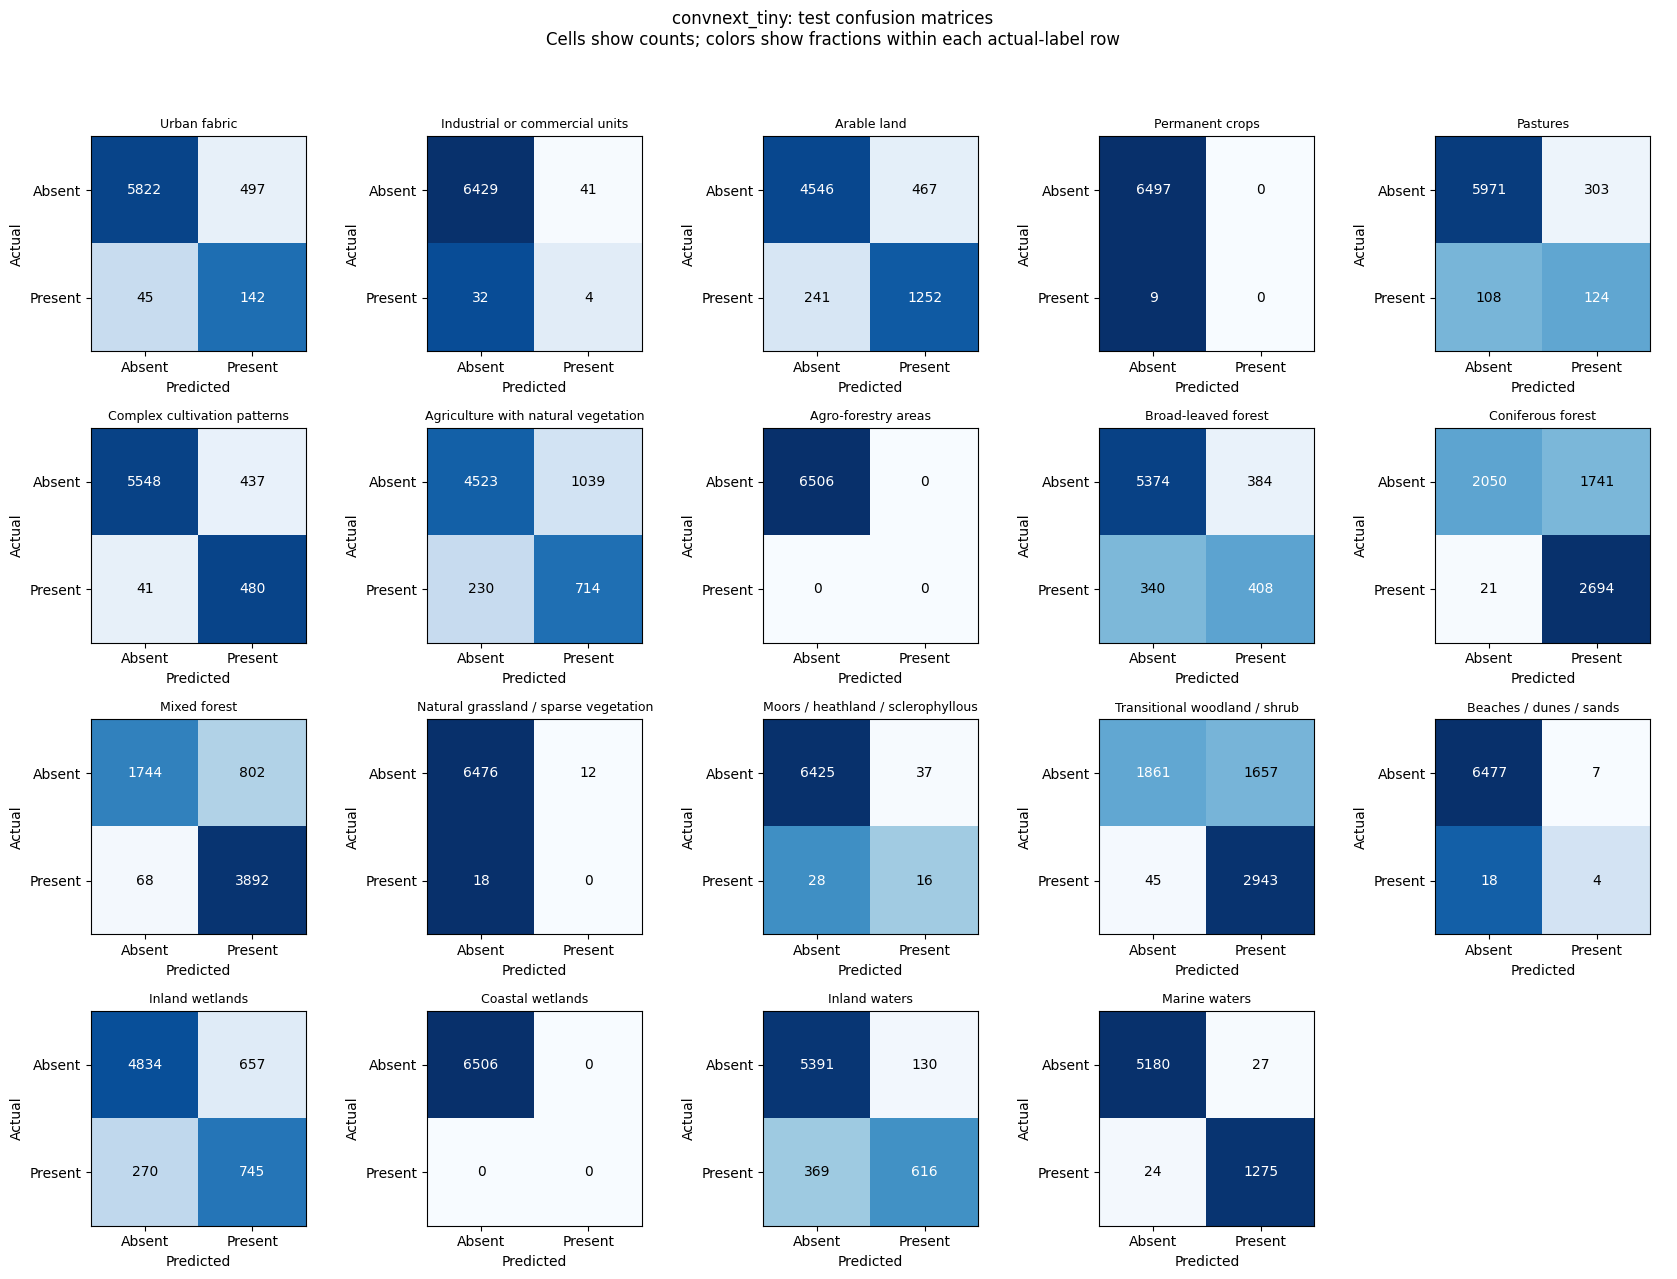

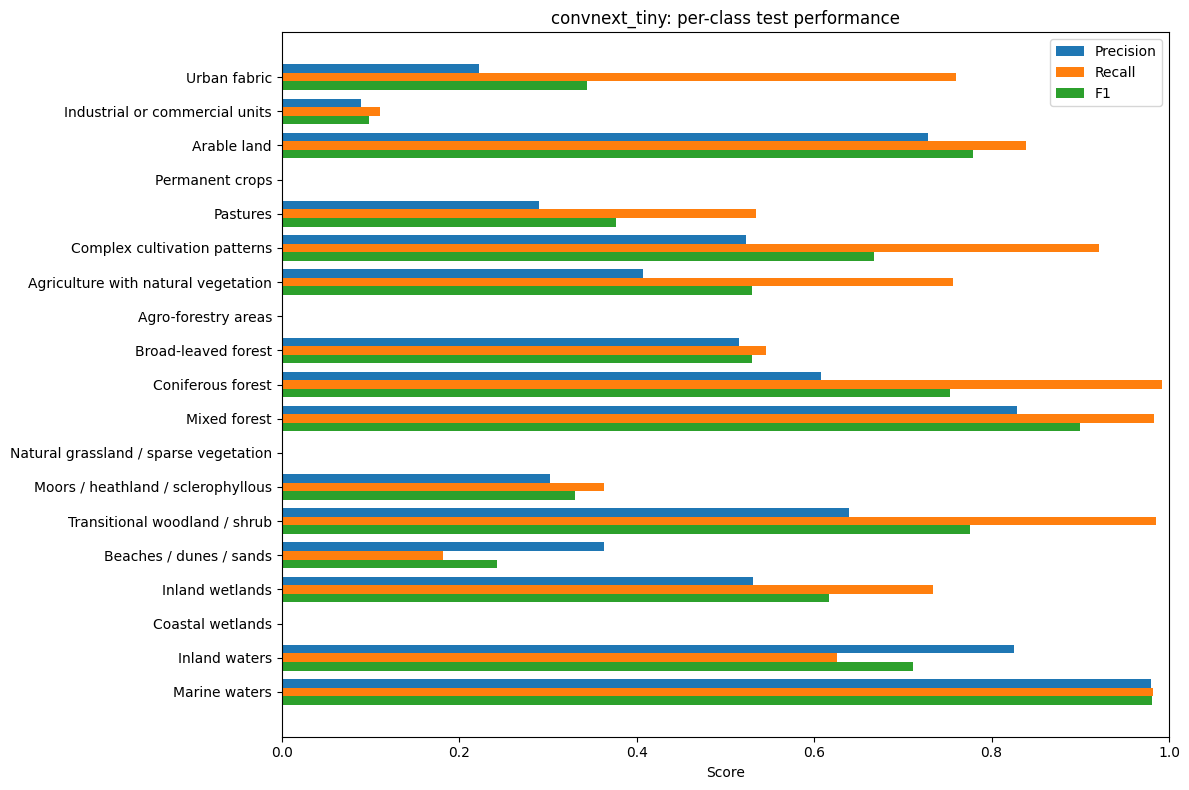


efficientnet_b0 — test threshold: 0.25


,class,TN,FP,FN,TP,test_positive_support,precision,recall,f1
0,Urban fabric,6026,293,48,139,187,0.3218,0.7433,0.4491
1,Industrial or commercial units,6357,113,19,17,36,0.1308,0.4722,0.2048
2,Arable land,4694,319,323,1170,1493,0.7858,0.7837,0.7847
3,Permanent crops,6497,0,9,0,9,0.0000,0.0000,0.0000
4,Pastures,6048,226,104,128,232,0.3616,0.5517,0.4369
5,Complex cultivation patterns,5703,282,127,394,521,0.5828,0.7562,0.6583
6,Agriculture with natural vegetation,5212,350,467,477,944,0.5768,0.5053,0.5387
7,Agro-forestry areas,6506,0,0,0,0,0.0000,0.0000,0.0000
8,Broad-leaved forest,5149,609,205,543,748,0.4714,0.7259,0.5716
9,Coniferous forest,2210,1581,56,2659,2715,0.6271,0.9794,0.7646


No positive test examples for: ['Agro-forestry areas', 'Coastal wetlands']
Recall/F1 for these labels are not meaningfully estimable.


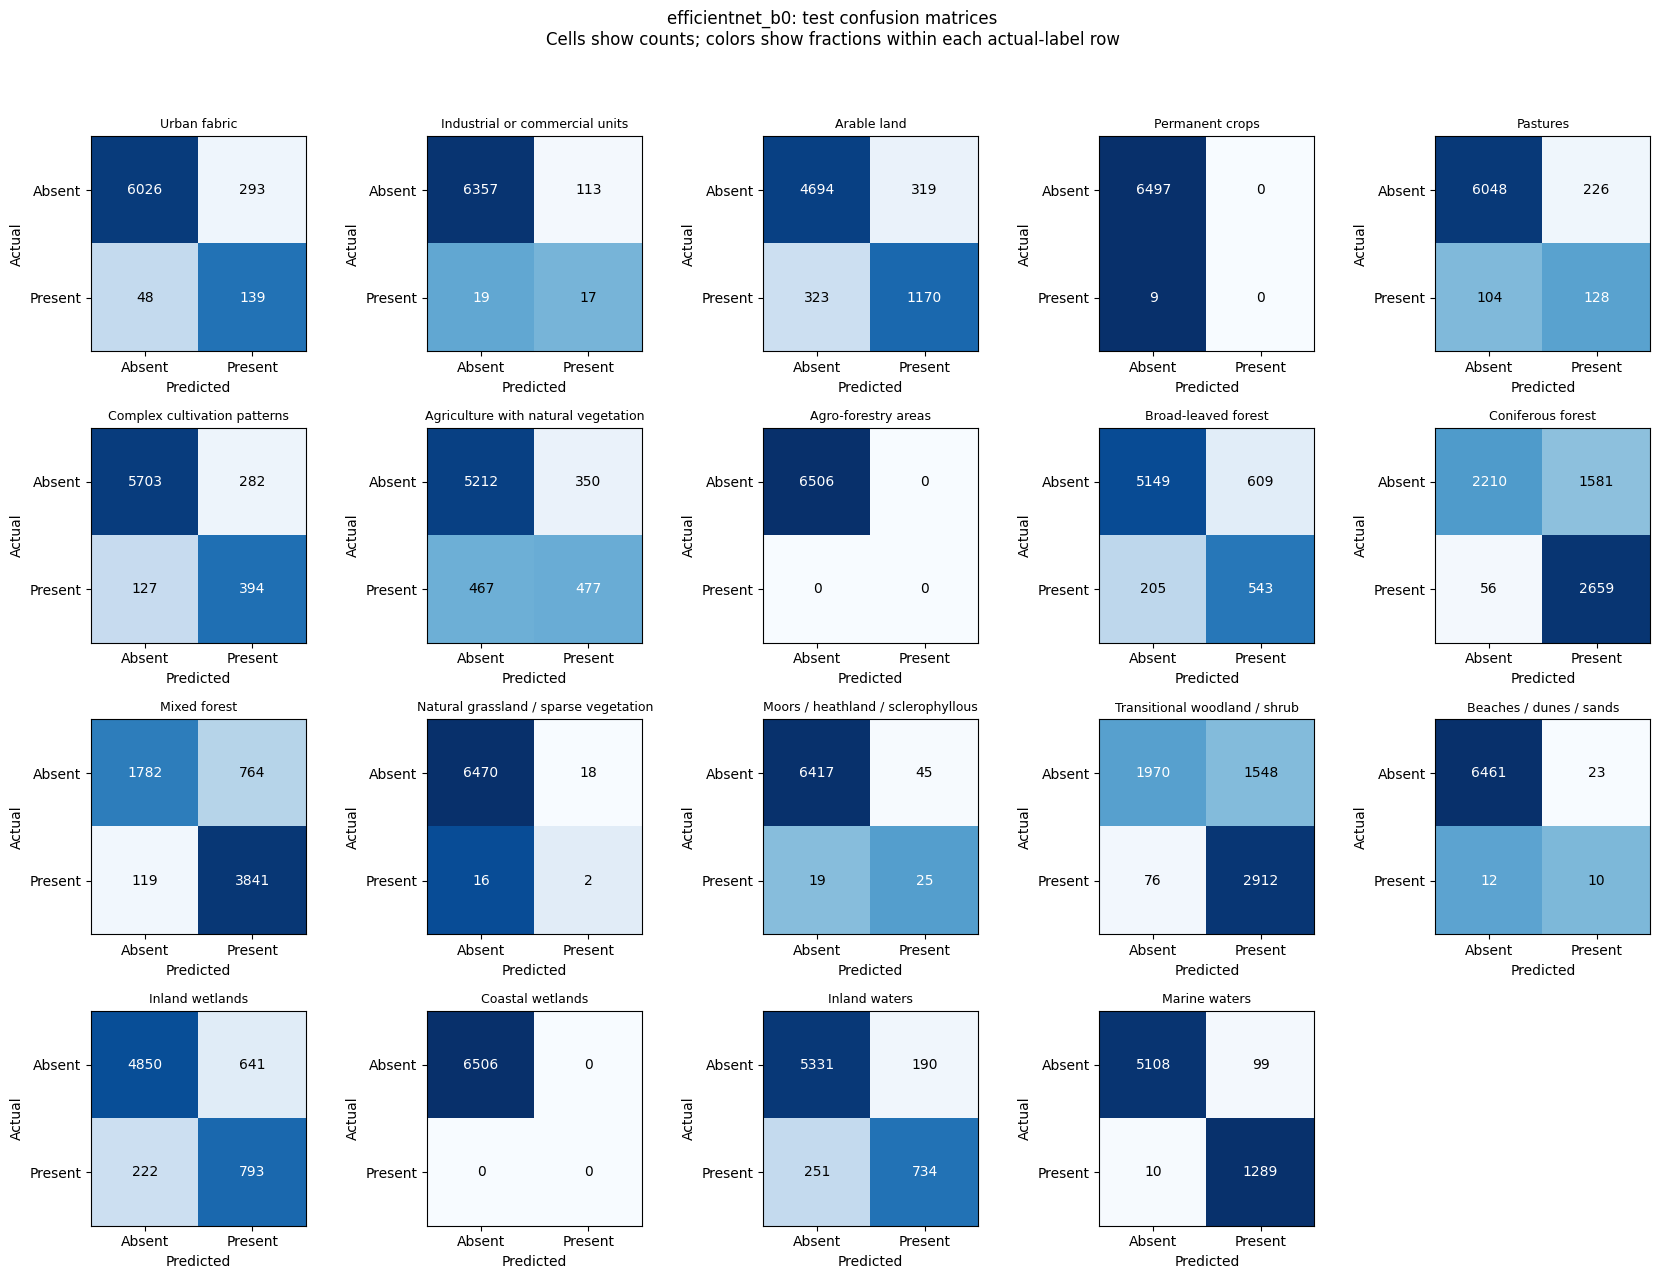

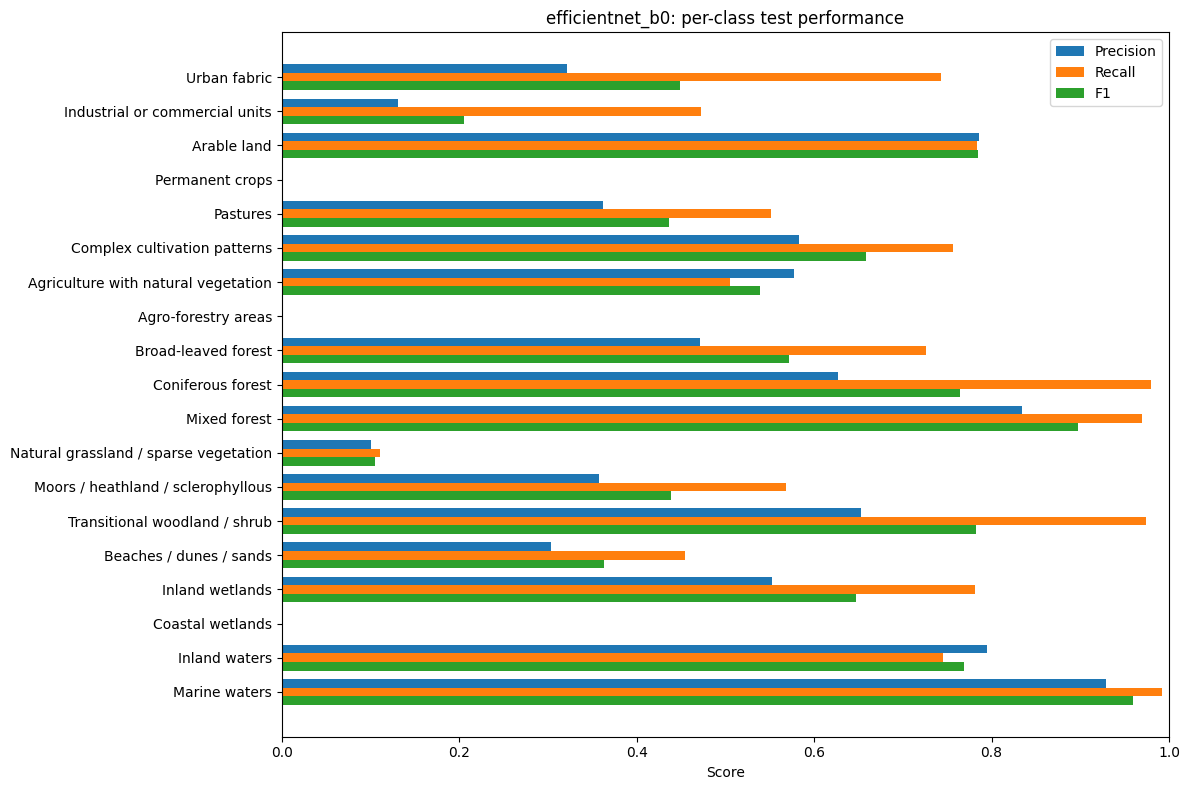


resnet50 — test threshold: 0.30


,class,TN,FP,FN,TP,test_positive_support,precision,recall,f1
0,Urban fabric,6206,113,83,104,187,0.4793,0.5561,0.5149
1,Industrial or commercial units,6409,61,24,12,36,0.1644,0.3333,0.2202
2,Arable land,4700,313,337,1156,1493,0.7869,0.7743,0.7806
3,Permanent crops,6497,0,9,0,9,0.0000,0.0000,0.0000
4,Pastures,5877,397,88,144,232,0.2662,0.6207,0.3726
5,Complex cultivation patterns,5595,390,53,468,521,0.5455,0.8983,0.6788
6,Agriculture with natural vegetation,5238,324,477,467,944,0.5904,0.4947,0.5383
7,Agro-forestry areas,6506,0,0,0,0,0.0000,0.0000,0.0000
8,Broad-leaved forest,5174,584,210,538,748,0.4795,0.7193,0.5754
9,Coniferous forest,2720,1071,178,2537,2715,0.7032,0.9344,0.8025


No positive test examples for: ['Agro-forestry areas', 'Coastal wetlands']
Recall/F1 for these labels are not meaningfully estimable.


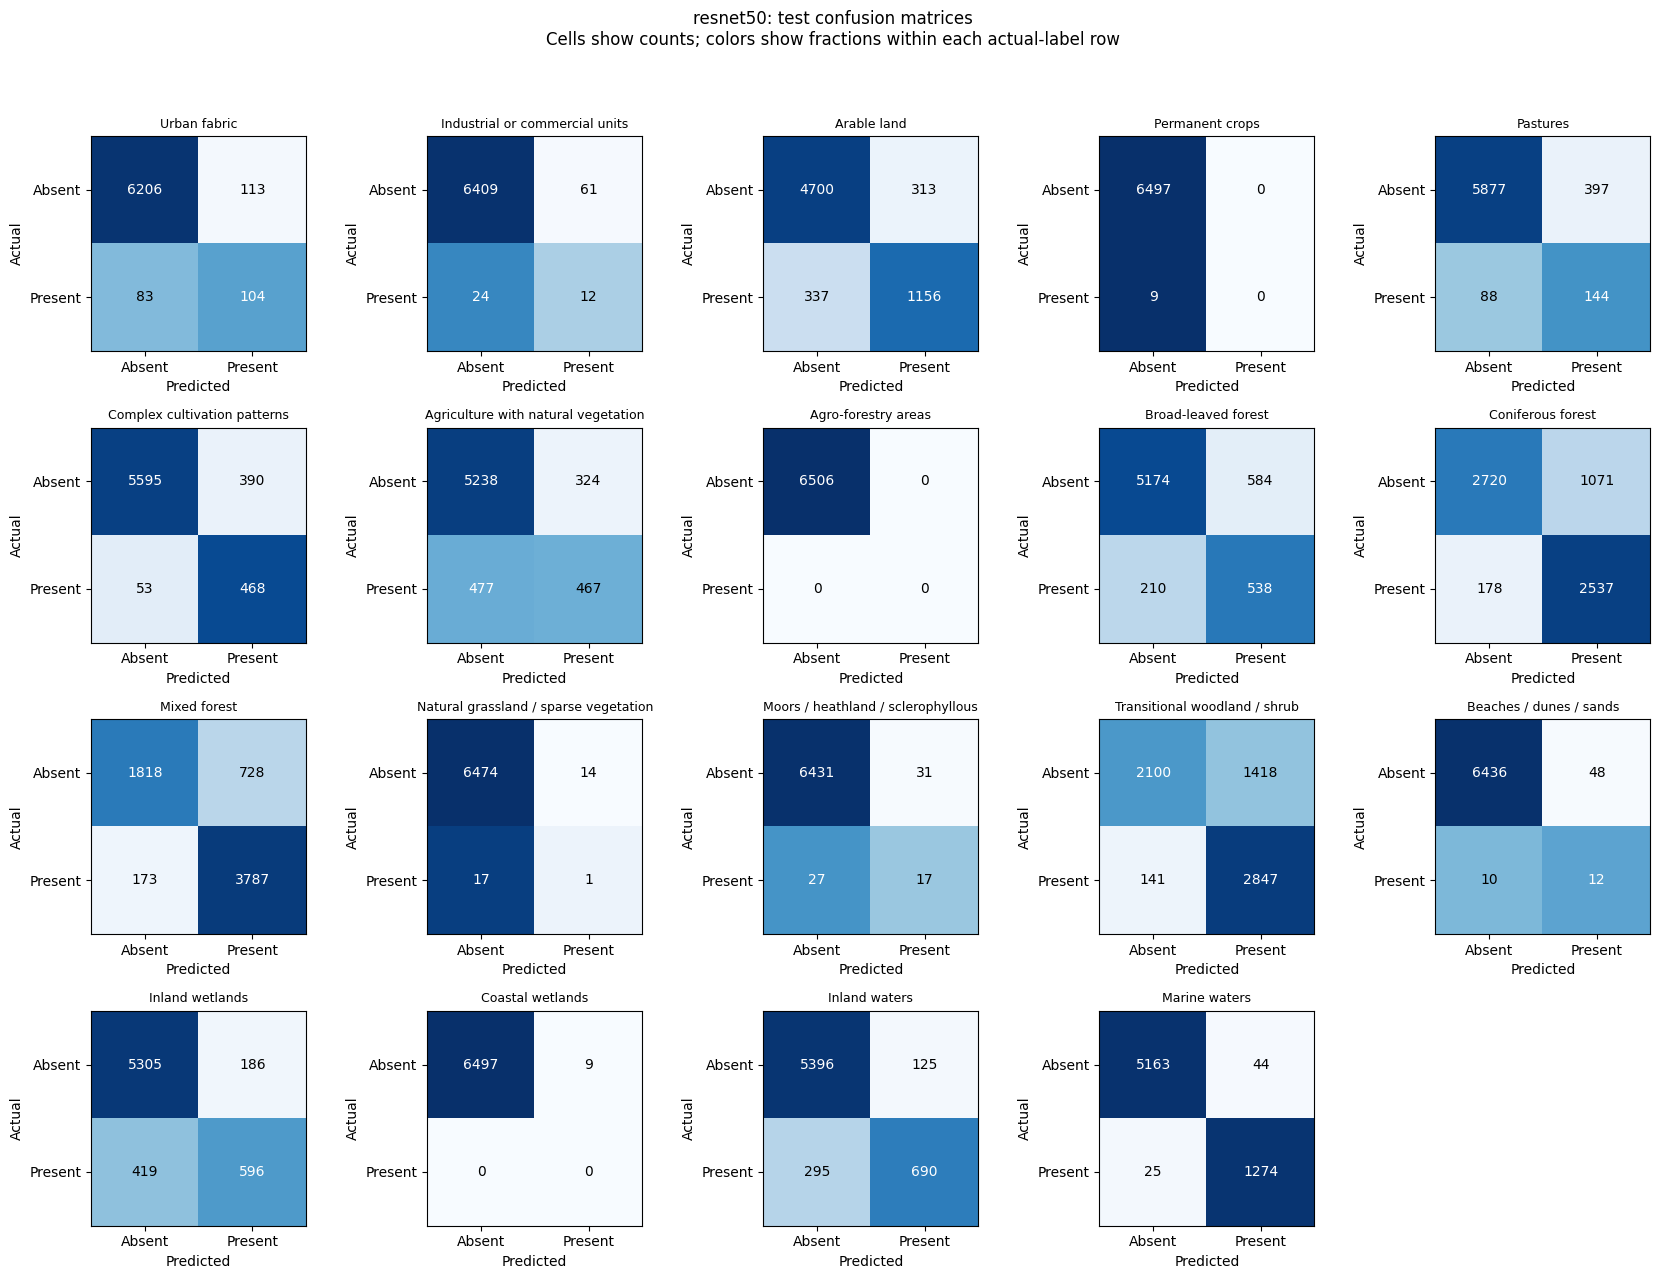

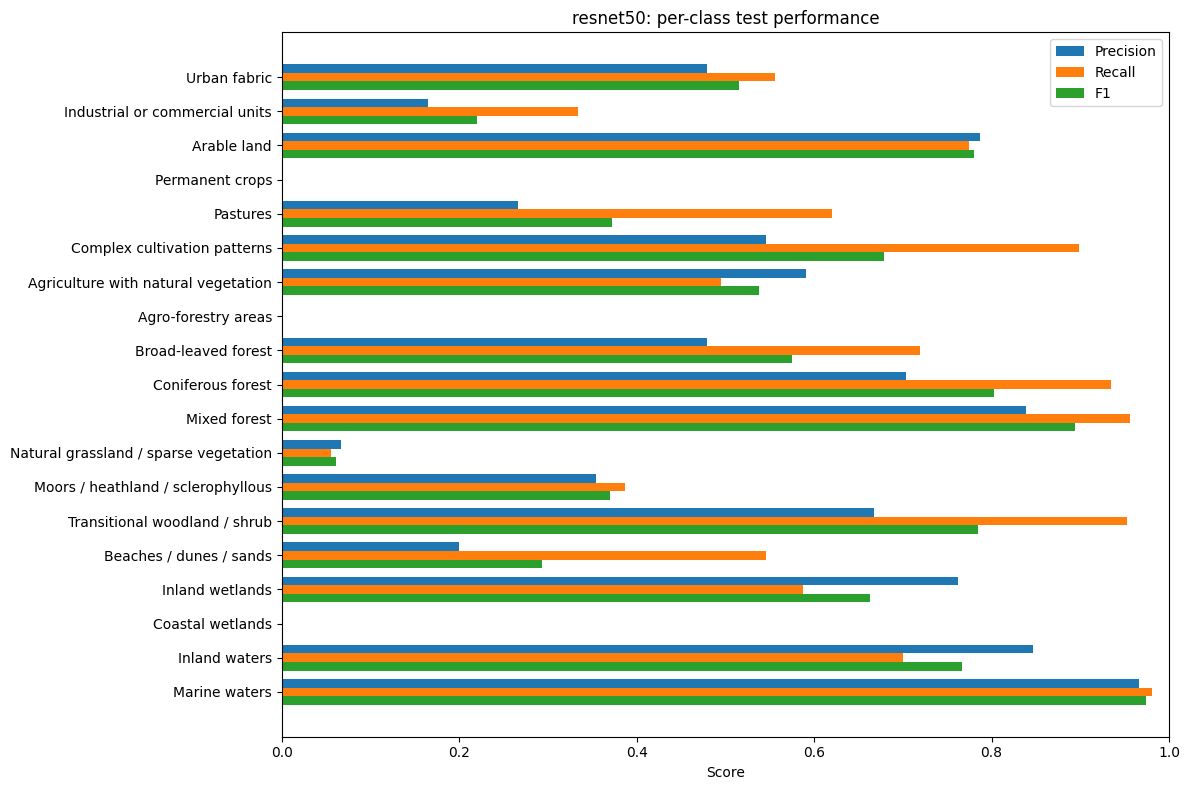

Updated results ZIP: /kaggle/working/BigEarthNet_Three_Baselines_Complete.zip


/kaggle/working/BigEarthNet_Three_Baselines_Complete.zip

In [24]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
)
from IPython.display import display, FileLink

ROOT = Path(
    "/kaggle/working/PALT_TGRS_results/drive_archives/"
    "three_additional_baselines/bigearthnet"
)

class_names = [
    "Urban fabric",
    "Industrial or commercial units",
    "Arable land",
    "Permanent crops",
    "Pastures",
    "Complex cultivation patterns",
    "Agriculture with natural vegetation",
    "Agro-forestry areas",
    "Broad-leaved forest",
    "Coniferous forest",
    "Mixed forest",
    "Natural grassland / sparse vegetation",
    "Moors / heathland / sclerophyllous",
    "Transitional woodland / shrub",
    "Beaches / dunes / sands",
    "Inland wetlands",
    "Coastal wetlands",
    "Inland waters",
    "Marine waters",
]

files = sorted(ROOT.glob(
    "BigEarthNet-S2/comparison/*/full/seed_13/predictions.npz"
))

if not files:
    raise FileNotFoundError("Saved baseline predictions were not found.")

for file in files:
    run_dir = file.parent
    model_name = run_dir.parent.parent.name

    with np.load(file) as saved:
        y = saved["targets"].astype(int)
        probabilities = saved["probabilities"]

    # Reuse the validation-selected threshold. Do not tune on test data.
    threshold = float(
        json.loads((run_dir / "threshold.json").read_text())["threshold"]
    )
    predicted = (probabilities >= threshold).astype(int)

    assert y.shape == predicted.shape
    assert y.shape[1] == 19
    assert np.isin(y, [0, 1]).all()

    matrices = multilabel_confusion_matrix(y, predicted)
    precision, recall, f1, support = precision_recall_fscore_support(
        y, predicted, average=None, zero_division=0
    )

    counts = pd.DataFrame({
        "class": class_names,
        "TN": matrices[:, 0, 0],
        "FP": matrices[:, 0, 1],
        "FN": matrices[:, 1, 0],
        "TP": matrices[:, 1, 1],
        "test_positive_support": support,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })
    counts.to_csv(
        run_dir / "per_label_confusion_counts.csv", index=False
    )

    print(f"\n{model_name} — test threshold: {threshold:.2f}")
    display(counts.round(4))

    absent = counts.loc[
        counts["test_positive_support"] == 0, "class"
    ].tolist()
    if absent:
        print("No positive test examples for:", absent)
        print("Recall/F1 for these labels are not meaningfully estimable.")

    # Per-label 2×2 confusion matrices.
    fig, axes = plt.subplots(4, 5, figsize=(17, 13))
    for i, ax in enumerate(axes.flat):
        if i >= len(class_names):
            ax.axis("off")
            continue

        cm = matrices[i]
        # Row-normalized color; annotations retain actual counts.
        normalized = np.divide(
            cm,
            cm.sum(axis=1, keepdims=True),
            out=np.zeros_like(cm, dtype=float),
            where=cm.sum(axis=1, keepdims=True) != 0,
        )

        ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
        for row in range(2):
            for col in range(2):
                ax.text(
                    col, row, str(cm[row, col]),
                    ha="center", va="center",
                    color="white" if normalized[row, col] > 0.5 else "black",
                )

        ax.set_title(class_names[i], fontsize=9)
        ax.set_xticks([0, 1], ["Absent", "Present"])
        ax.set_yticks([0, 1], ["Absent", "Present"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    fig.suptitle(
        f"{model_name}: test confusion matrices\n"
        "Cells show counts; colors show fractions within each actual-label row"
    )
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(
        run_dir / "per_label_confusion_matrices.png",
        dpi=180, bbox_inches="tight"
    )
    display(fig)
    plt.close(fig)

    # Per-class precision, recall and F1.
    fig, ax = plt.subplots(figsize=(12, 8))
    positions = np.arange(19)
    ax.barh(positions - 0.25, precision, height=0.25, label="Precision")
    ax.barh(positions, recall, height=0.25, label="Recall")
    ax.barh(positions + 0.25, f1, height=0.25, label="F1")
    ax.set_yticks(positions, class_names)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Score")
    ax.set_title(f"{model_name}: per-class test performance")
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        run_dir / "per_class_precision_recall_f1.png",
        dpi=180, bbox_inches="tight"
    )
    display(fig)
    plt.close(fig)

# Recreate the ZIP to include these new figures and tables.
zip_path = shutil.make_archive(
    "/kaggle/working/BigEarthNet_Three_Baselines_Complete",
    "zip",
    root_dir=str(ROOT),
)
print("Updated results ZIP:", zip_path)
display(FileLink(zip_path))